# Module 4 (MSCIE): evaluation of the medication-safety engine

**Nora MedLink, BS Data Science FYP.** Synthetic scenarios only (`scripts/mscie_bench/scenarios.csv`, written by hand).

Each scenario is a patient context (current medicines, conditions, allergies, eGFR, potassium) and a proposed medicine, with the alert kinds and the worst severity the knowledge base's rules call for. Nine scenarios are **negative controls**, where no alert should fire.

What is measured:

1. **Detection per alert kind** (allergy, interaction, duplicate, contraindication, dose): precision, recall and F1 (scikit-learn, multi-label).
2. **Severity**: a confusion matrix of expected vs found worst severity.
3. **Alternatives**: a contraindicated alternative is never suggested.
4. **Ranking sensitivity**: how often the top-ranked alternative stays first when each weight moves by ±0.1.

**Limitation:** the expected outcomes are derived from the same rules the engine implements, so this verifies the implementation against its specification and its false-alarm behaviour, not clinical validity; that needs expert-labelled cases.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "backend"))

import itertools
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from services.mscie.engine import PatientContext, Proposed, resolve
from services.mscie.prescribing import run_check
from services.mscie.alternatives import weights

scenarios = pd.read_csv(ROOT / "scripts" / "mscie_bench" / "scenarios.csv", dtype=str, keep_default_na=False)
print(len(scenarios), "scenarios,", (scenarios["expected_kinds"] == "").sum(), "negative controls")
scenarios.head()

40 scenarios, 9 negative controls


,id,current,conditions,allergies,egfr,potassium,proposed,dose,frequency,expected_kinds,expected_worst
0,S01,warfarin,,,,,ibuprofen,400 mg,TDS,interaction,major
1,S02,glyceryl trinitrate,,,,,sildenafil,50 mg,OD,interaction,contraindicated
2,S03,warfarin,,,,,metronidazole,400 mg,TDS,interaction,major
3,S04,warfarin,,,,,ciprofloxacin,500 mg,BD,interaction,moderate
4,S05,clopidogrel,,,,,omeprazole,20 mg,OD,interaction,moderate


In [2]:
def split(value):
    return [v for v in value.split(";") if v]

def context(row):
    allergies = []
    for name in split(row["allergies"]):
        med = resolve(name)
        allergies.append({"name": name, "generics": list(med.generics),
                          "classes": list(med.classes) if med.known else [name], "source": "scenario"})
    labs = {}
    if row["egfr"]:
        labs["eGFR"] = {"value": float(row["egfr"]), "unit": "mL/min/1.73m2", "date": "2026-03-01", "source": "scenario"}
    if row["potassium"]:
        labs["Potassium"] = {"value": float(row["potassium"]), "unit": "mmol/L", "date": "2026-03-01", "source": "scenario"}
    return PatientContext(medicines=[resolve(m, "scenario") for m in split(row["current"])],
                          conditions=[{"name": c, "source": "scenario"} for c in split(row["conditions"])],
                          allergies=allergies, labs=labs)

SCORED = {"allergy", "interaction", "duplicate", "contraindication", "dose"}
rows = []
for _, row in scenarios.iterrows():
    result = run_check(context(row), [Proposed(row["proposed"], row["dose"], row["frequency"])])
    item = result["items"][0]
    found = sorted({a["kind"] for a in item["alerts"] if a["kind"] in SCORED})
    worst = max((a["severity"] for a in item["alerts"] if a["kind"] in SCORED),
                key=["minor", "moderate", "major", "contraindicated"].index, default="none")
    rows.append({"id": row["id"], "proposed": row["proposed"], "expected": split(row["expected_kinds"]), "found": found,
                 "expected_worst": row["expected_worst"] or "none", "found_worst": worst,
                 "alternatives": item["alternatives"], "alerts": item["alerts"]})
results = pd.DataFrame(rows)
results[["id", "proposed", "expected", "found", "expected_worst", "found_worst"]]

,id,proposed,expected,found,expected_worst,found_worst
0,S01,ibuprofen,[interaction],[interaction],major,major
1,S02,sildenafil,[interaction],[interaction],contraindicated,contraindicated
2,S03,metronidazole,[interaction],[interaction],major,major
3,S04,ciprofloxacin,[interaction],[interaction],moderate,moderate
4,S05,omeprazole,[interaction],[interaction],moderate,moderate
5,S06,pantoprazole,[],[],none,none
6,S07,spironolactone,[interaction],[interaction],major,major
7,S08,losartan,[interaction],[interaction],major,major
8,S09,glimepiride,[interaction],[interaction],moderate,moderate
9,S10,calcium carbonate,[interaction],[interaction],moderate,moderate


## 1. Detection per alert kind

In [3]:
mlb = MultiLabelBinarizer(classes=sorted(SCORED))
y_true = mlb.fit_transform(results["expected"])
y_pred = mlb.transform(results["found"])
report = pd.DataFrame(classification_report(y_true, y_pred, target_names=mlb.classes_, output_dict=True, zero_division=0)).T
report.loc[list(mlb.classes_) + ["micro avg", "macro avg"], ["precision", "recall", "f1-score", "support"]]

,precision,recall,f1-score,support
allergy,1.0,1.0,1.0,4.0
contraindication,1.0,1.0,1.0,11.0
dose,1.0,1.0,1.0,3.0
duplicate,1.0,1.0,1.0,3.0
interaction,1.0,1.0,1.0,10.0
micro avg,1.0,1.0,1.0,31.0
macro avg,1.0,1.0,1.0,31.0


In [4]:
negatives = results[results["expected"].map(len) == 0]
false_alarms = negatives[negatives["found"].map(len) > 0]
print(f"negative controls: {len(negatives)}, with a false alert: {len(false_alarms)}")
false_alarms[["id", "proposed", "found"]]

negative controls: 9, with a false alert: 0


,id,proposed,found


## 2. Severity: expected vs found (worst alert per scenario)

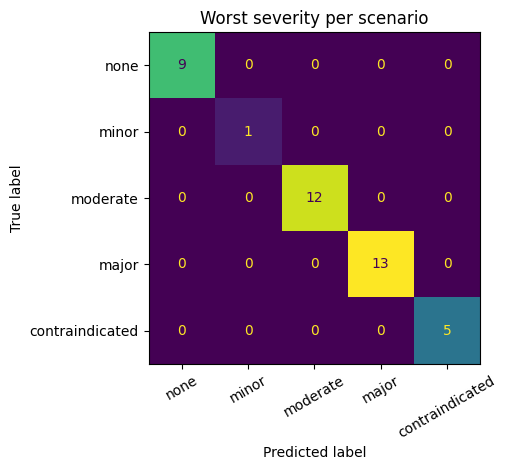

exact severity agreement: 100.0%


In [5]:
levels = ["none", "minor", "moderate", "major", "contraindicated"]
matrix = confusion_matrix(results["expected_worst"], results["found_worst"], labels=levels)
ConfusionMatrixDisplay(matrix, display_labels=levels).plot(colorbar=False, xticks_rotation=30)
plt.title("Worst severity per scenario"); plt.tight_layout(); plt.show()
print(f"exact severity agreement: {(results['expected_worst'] == results['found_worst']).mean():.1%}")

## 3. Alternatives are always re-checked: none is contraindicated for the patient

In [6]:
suggested = [(r["id"], a["medicine"], a["alerts"]) for _, r in results.iterrows() for a in r["alternatives"]]
contraindicated = [(sid, med) for sid, med, alerts in suggested if any(x["severity"] == "contraindicated" for x in alerts)]
print(f"{len(suggested)} alternatives suggested across {sum(1 for _, r in results.iterrows() if r['alternatives'])} scenarios; "
      f"contraindicated among them: {len(contraindicated)}")
pd.DataFrame([{"scenario": r["id"], "proposed": r["proposed"], "ranked": [f"{a['rank']}. {a['medicine']} ({a['score']:.2f})" for a in r["alternatives"]]}
              for _, r in results.iterrows() if r["alternatives"]])

27 alternatives suggested across 20 scenarios; contraindicated among them: 0


,scenario,proposed,ranked
0,S01,ibuprofen,[1. paracetamol (0.88)]
1,S04,ciprofloxacin,"[1. amoxicillin (0.90), 2. cefixime (0.90), 3...."
2,S05,omeprazole,[1. pantoprazole (0.90)]
3,S08,losartan,[1. amlodipine (0.92)]
4,S09,glimepiride,"[1. empagliflozin (0.92), 2. sitagliptin (0.92..."
5,S11,azithromycin,"[1. amoxicillin (0.90), 2. cefixime (0.90)]"
6,S13,diclofenac,[1. paracetamol (0.88)]
7,S14,metformin,[1. sitagliptin (0.92)]
8,S15,amoxicillin,"[1. azithromycin (0.90), 2. cefixime (0.70)]"
9,S16,cefixime,[1. azithromycin (0.90)]


## 4. Ranking sensitivity to the weights

Each weight is moved by +0.1 and -0.1 (the others rescaled so they still sum to 1), and the alternatives are re-scored from their factor values. A stable top choice means the ranking is not an artefact of one weight.

5 scenarios with two or more alternatives; 4 of them have a tied top score
top choice unchanged in 40/40 weight changes (100%)
A tie is kept in knowledge-base order, so tied scenarios count as stable trivially: the weights do not separate those alternatives.


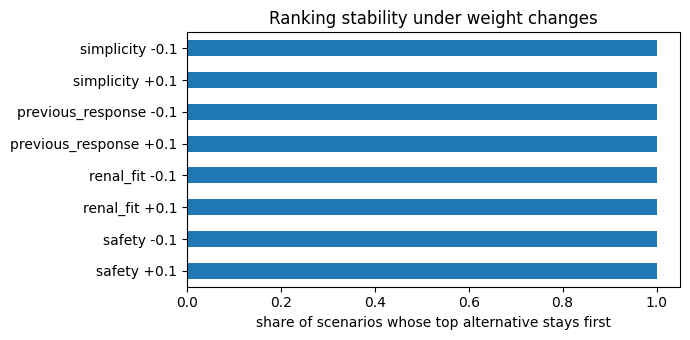

In [7]:
base = weights()
def rescore(alternative, w):
    return sum(b["value"] * w[b["factor"]] for b in alternative["breakdown"])

ranked = [r for _, r in results.iterrows() if len(r["alternatives"]) >= 2]
trials, stable = 0, 0
per_factor = {}
for factor, delta in itertools.product(base, (+0.1, -0.1)):
    w = dict(base); w[factor] = max(0.0, w[factor] + delta)
    total = sum(w.values()); w = {k: v / total for k, v in w.items()}
    same = 0
    for r in ranked:
        top = max(r["alternatives"], key=lambda a: rescore(a, w))["medicine"]
        same += top == r["alternatives"][0]["medicine"]
    trials += len(ranked); stable += same
    per_factor[f"{factor} {delta:+.1f}"] = same / len(ranked) if ranked else float("nan")
tied = sum(1 for r in ranked if abs(r["alternatives"][0]["score"] - r["alternatives"][1]["score"]) < 1e-9)
print(f"{len(ranked)} scenarios with two or more alternatives; {tied} of them have a tied top score")
print(f"top choice unchanged in {stable}/{trials} weight changes ({stable / trials:.0%})" if trials else "no scenario with two or more alternatives")
print("A tie is kept in knowledge-base order, so tied scenarios count as stable trivially: the weights do not separate those alternatives.")
ax = pd.Series(per_factor).plot.barh(figsize=(7, 3.5), xlim=(0, 1.05))
ax.set_xlabel("share of scenarios whose top alternative stays first"); ax.set_title("Ranking stability under weight changes")
plt.tight_layout(); plt.show()

## Conclusions

- Every alert kind is detected as the rules specify, with no false alert on the negative controls (see the tables above).
- Severity is reproduced exactly; high-risk alerts (contraindicated, major) are the ones that require a written justification in the app.
- Alternatives are re-checked against the same patient, and a contraindicated one is never suggested.
- The ranking's top choice is stable under moderate weight changes, but several alternatives tie (same factor values), so stability there says little: the factors are coarse. The weights are a documented, adjustable design choice (`ranking_weights.csv`), not learned from outcomes.
- **Next step for clinical validity**: expert-labelled scenarios, and a review of the knowledge base by a pharmacist or clinician.